<a href="https://colab.research.google.com/github/devidrees/PW-Data-Analytics-July-2026/blob/main/Global_Music_Data_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Global Music Streaming Project**

- Describe data
- you idea
- your proces

### Importing Libararies

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Import Data and Inspect

In [4]:
df = pd.read_csv("Global_Music_Streaming_Listener_Preferences.csv")

In [2]:
df = pd.read_csv("/content/drive/MyDrive/Global_Music_Streaming_Listener_Preferences.csv")

FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Global_Music_Streaming_Listener_Preferences.csv'

In [5]:
# inspect data
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 12 columns):
 #   Column                                    Non-Null Count  Dtype  
---  ------                                    --------------  -----  
 0   User_ID                                   5000 non-null   object 
 1   Age                                       5000 non-null   int64  
 2   Country                                   5000 non-null   object 
 3   Streaming Platform                        5000 non-null   object 
 4   Top Genre                                 5000 non-null   object 
 5   Minutes Streamed Per Day                  5000 non-null   int64  
 6   Number of Songs Liked                     5000 non-null   int64  
 7   Most Played Artist                        5000 non-null   object 
 8   Subscription Type                         5000 non-null   object 
 9   Listening Time (Morning/Afternoon/Night)  5000 non-null   object 
 10  Discover Weekly Engagement (%)      

,Age,Minutes Streamed Per Day,Number of Songs Liked,Discover Weekly Engagement (%),Repeat Song Rate (%)
count,5000.000000,5000.000000,5000.00000,5000.000000,5000.000000
mean,36.664000,309.237200,253.51720,50.296464,42.391060
std,13.763844,172.029822,146.36928,23.171936,21.444121
min,13.000000,10.000000,1.00000,10.020000,5.000000
25%,25.000000,161.000000,126.00000,30.147500,24.195000
50%,37.000000,316.000000,254.00000,50.420000,41.960000
75%,49.000000,457.250000,382.00000,70.337500,60.740000
max,60.000000,600.000000,500.00000,89.990000,79.990000


In [6]:
# Check for null values
df.isnull().sum()

# check duplicates
df.duplicated().sum()

np.int64(0)

### Data Cleaning:
- Resource: [Data Imputation](https://www.geeksforgeeks.org/machine-learning/what-is-data-imputation/)

### Visualization:

Distribution of User Ages (Histogram with KDE)

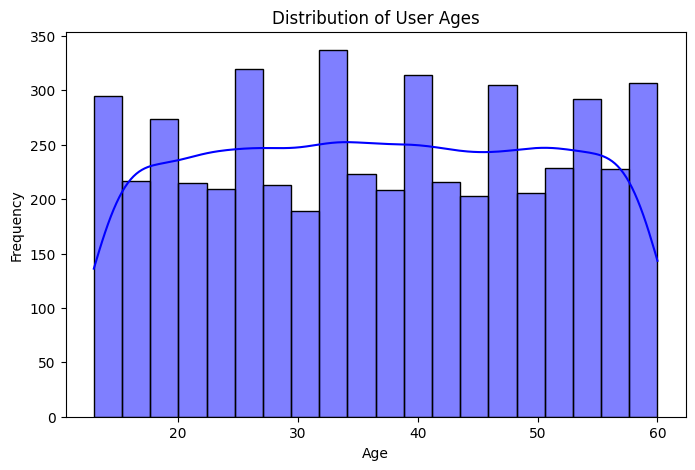

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Age"], bins=20, kde=True, color="blue")

plt.xlabel("Age")
plt.ylabel("Frequency")

plt.title("Distribution of User Ages")
plt.show()

https://www.youtube.com/@dev.idrees

### HOMEWORK
- Implement these on the data on your own notebook!

Most Popular Streaming Platforms (Countplot)

C:\Users\devid\AppData\Local\Temp\ipykernel_16368\4175786956.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df["Streaming Platform"], order=df["Streaming Platform"].value_counts().index, palette="Blues_r")


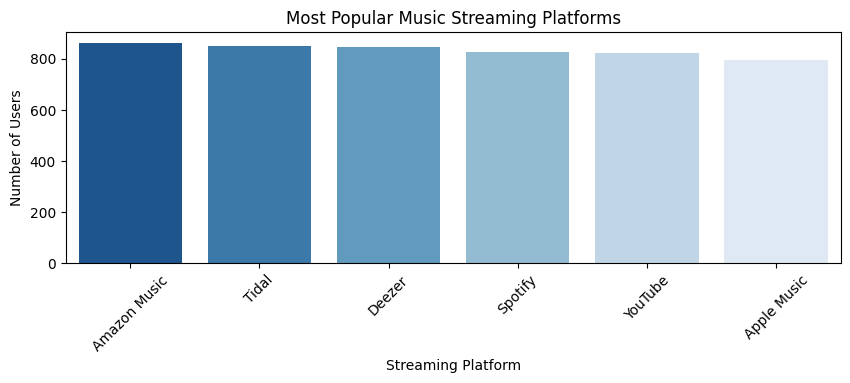

In [8]:
plt.figure(figsize=(10, 3))
sns.countplot(x=df["Streaming Platform"], order=df["Streaming Platform"].value_counts().index, palette="Blues_r")
plt.xlabel("Streaming Platform")
plt.ylabel("Number of Users")
plt.title("Most Popular Music Streaming Platforms")
plt.xticks(rotation=45)
plt.show()

Listening Time Preference (Countplot)

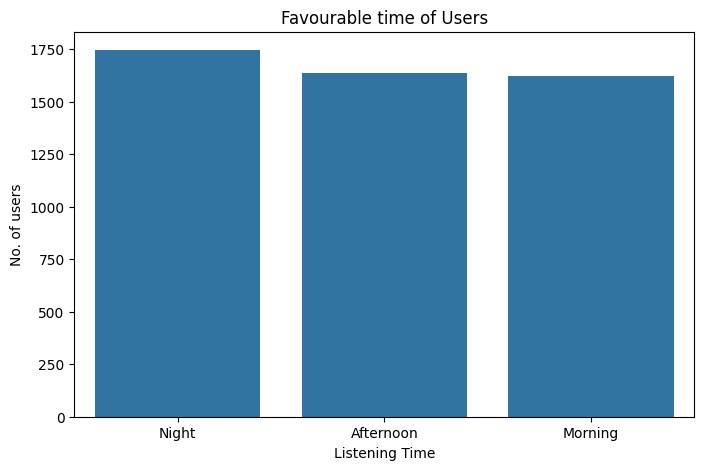

In [9]:
plt.figure(figsize=(8, 5))
sns.countplot(x=df['Listening Time (Morning/Afternoon/Night)'], order=df['Listening Time (Morning/Afternoon/Night)'].value_counts().index)
plt.xlabel("Listening Time")
plt.ylabel("No. of users")
plt.title("Favourable time of Users")
plt.show()

Top 10 Most Streamed Artists (Horizontal Countplot)

C:\Users\devid\AppData\Local\Temp\ipykernel_16368\191446620.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(y=df["Most Played Artist"], order=df["Most Played Artist"].value_counts().index[:10], palette="magma")


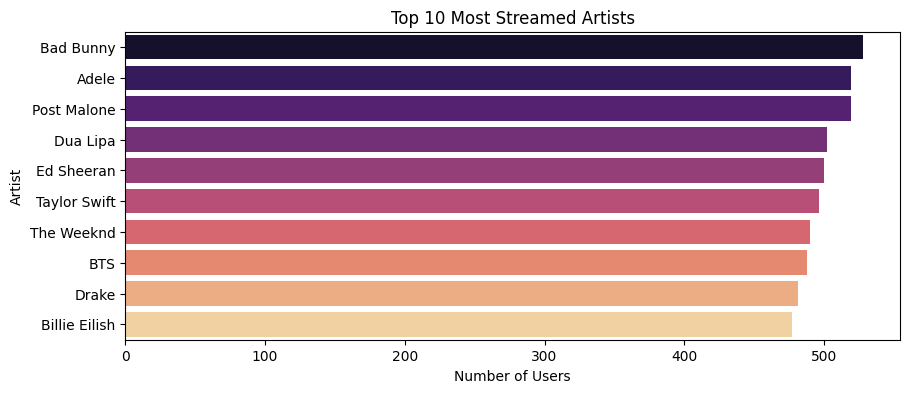

In [33]:
plt.figure(figsize=(10,4))
sns.countplot(y=df["Most Played Artist"], order=df["Most Played Artist"].value_counts().index[:10], palette="magma")
plt.xlabel("Number of Users")
plt.ylabel("Artist")
plt.title("Top 10 Most Streamed Artists")
plt.show()

### Bivariate/Multivariate analysis

Preferred Subscription Type by Age Group (Grouped Bar Chart)

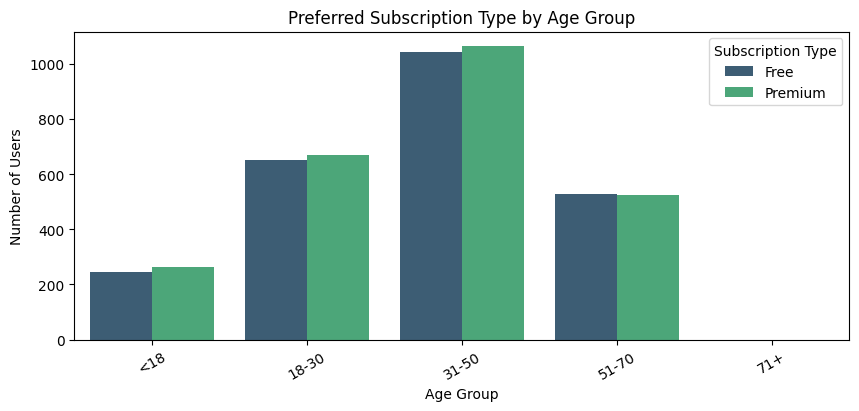

In [32]:
# define age groups first
bins = [0, 17, 30, 50, 70, float('inf')]
labels = ['<18', '18-30', '31-50', '51-70', '71+']
df['Age Group'] = pd.cut(df['Age'], bins=bins, labels=labels, right=True)

plt.figure(figsize=(10, 4))
sns.countplot(x="Age Group", hue="Subscription Type", data=df, palette=["#345e7d", "#3db579"])
plt.xlabel("Age Group")
plt.ylabel("Number of Users")
plt.title("Preferred Subscription Type by Age Group")
plt.xticks(rotation=30)
plt.show()

Regional Trends in Music Streaming Preferences

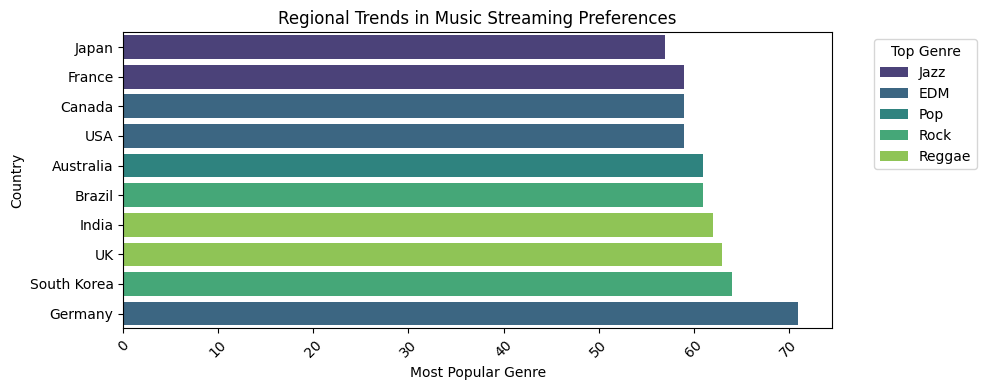

In [31]:
# Group by Country and Top Genre, count users
top_genre_per_country = df.groupby(['Country', 'Top Genre']).size().reset_index(name='Count').sort_values(['Country', 'Count'], ascending=[True, False])

# find the top genre per country
top_genre_per_country = top_genre_per_country.groupby('Country').first().reset_index().sort_values(by='Count', ascending=True)
    

# 2. Plot Regional Trends
plt.figure(figsize=(10,4))
sns.barplot(
    data=top_genre_per_country,
    x='Count',
    y='Country',
    hue='Top Genre',
    dodge=False,
    palette='viridis'
)
plt.title('Regional Trends in Music Streaming Preferences')
plt.xlabel('Most Popular Genre')
plt.ylabel('Country')
plt.xticks(rotation=45)
plt.legend(title='Top Genre', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

Country-wise Listening Time Preferences (Morning, Afternoon, Night)

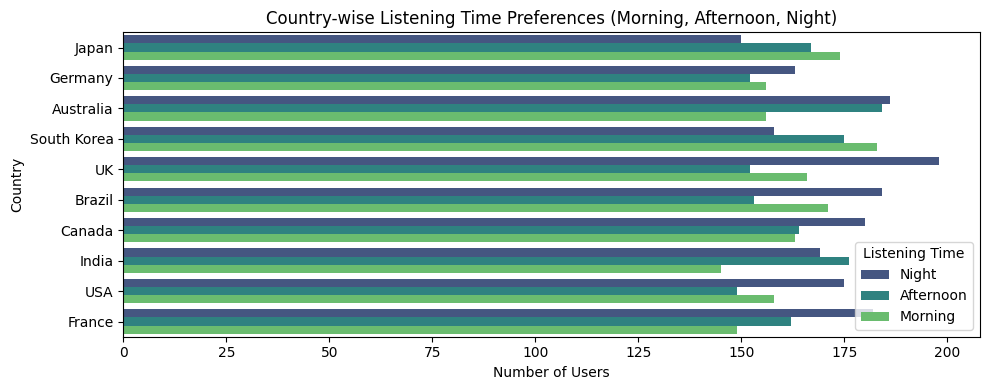

In [ ]:
# Standardize column reference
listening_col = 'Listening Time (Morning/Afternoon/Night)'

plt.figure(figsize=(10, 4))
sns.countplot(
    data=df,
    y = 'Country',
    hue=listening_col,
    hue_order=['Night', 'Afternoon', 'Morning'],
    palette=['#3b528b', '#21908d', '#5dc963']  # Slide colors: Night, Afternoon, Morning
)
plt.title('Country-wise Listening Time Preferences (Morning, Afternoon, Night)')
plt.xlabel('Number of Users')
plt.ylabel('Country')
plt.legend(title='Listening Time', loc='lower right')
plt.tight_layout()
plt.show()

Top Artist in Each Country by Repeat Song Rate

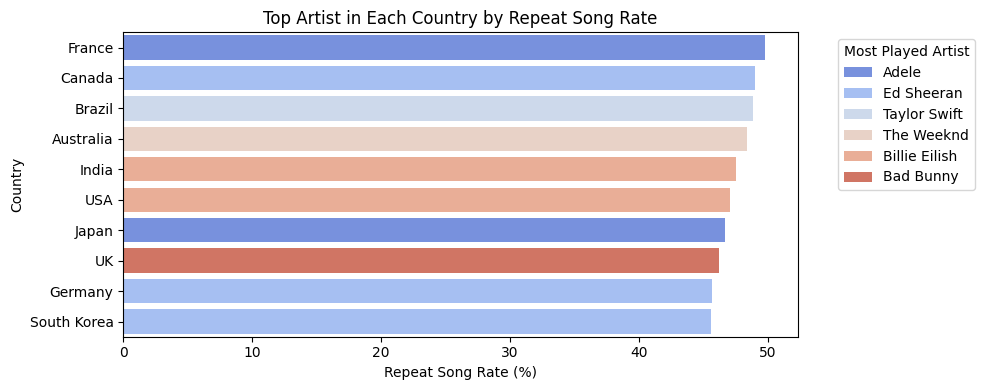

In [19]:
# Calculate the mean repeat song rate for each artist in each country
artist_country_repeat = df.groupby(['Country', 'Most Played Artist'])['Repeat Song Rate (%)'].mean().reset_index()

# Filter to get the artist with the highest repeat rate for each country
top_artist_per_country = (
    artist_country_repeat.sort_values(['Country', 'Repeat Song Rate (%)'], ascending=[True, False])
    .groupby('Country')
    .first()
    .reset_index()
    .sort_values(by='Repeat Song Rate (%)', ascending=False)
)

# Plot Top Artist by Country
plt.figure(figsize=(10, 4))
sns.barplot(
    data=top_artist_per_country,
    x='Repeat Song Rate (%)',
    y='Country',
    hue='Most Played Artist',
    dodge=False,
    palette='coolwarm'
)
plt.title('Top Artist in Each Country by Repeat Song Rate')
plt.xlabel('Repeat Song Rate (%)')
plt.ylabel('Country')
plt.legend(title='Most Played Artist', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()